# Explainable AI: één predictie, twee verklaringen

**Topic 2 — PXL · SHAP en LIME op tabulaire data**

---

## Waarom explainable AI?

Moderne modellen (random forests, gradient boosting, neurale netwerken) zijn vaak *black boxes*:
je stopt er features in, er komt een predictie uit, maar **waarom** die predictie?

Dat "waarom" is om drie redenen belangrijk:

| Reden | Voorbeeld |
|---|---|
| **Vertrouwen** | Een arts gebruikt een model alleen als ze begrijpt waarop het zich baseert. |
| **Debuggen** | Als het model vooral kijkt naar het patiëntnummer, heb je *data leakage*. |
| **Wetgeving** | AVG/GDPR art. 22 en de EU AI Act eisen uitleg bij geautomatiseerde beslissingen. |

## Twee assen om uitlegmethodes in te delen

1. **Globaal vs. lokaal**
   - *Globaal*: hoe gedraagt het model zich in het algemeen? ("Welke features zijn belangrijk?")
   - *Lokaal*: waarom kreeg **deze ene** rij **deze** predictie?
2. **Model-specifiek vs. model-agnostisch**
   - *Model-specifiek*: gebruikt de interne structuur (bv. de boomsplits van een random forest). Snel en exact.
   - *Model-agnostisch*: behandelt het model als een functie `x -> predictie`. Werkt op álles, maar is een benadering.

## De opzet van deze notebook

We nemen **één dataset**, **één model** en **één patiënt**, en verklaren die predictie op
**twee manieren**. Beide methodes krijgen exact dezelfde vijfdelige structuur, zodat je ze
kunt vergelijken:

> **1. Het idee** → **2. De explainer opzetten** → **3. Globale uitleg** →
> **4. Lokale uitleg van onze patiënt**

Bij LIME staan 3 en 4 omgedraaid: je moet eerst één uitleg gezien hebben voor je begrijpt
waarom je ze niet mag samenvoegen. En LIME krijgt een vijfde stuk (§4.5), omdat je daar zelf
moet nagaan of de uitleg te vertrouwen is.

| | **SHAP** | **LIME** |
|---|---|---|
| Idee | Speltheorie: verdeel de predictie eerlijk over de features | Train een simpel model dat lokaal lijkt op het complexe model |
| Bibliotheek | `shap` | `lime` |
| Snelheid | Traag in het algemeen, **snel voor bomen** (`TreeExplainer`) | Redelijk snel, maar per instantie opnieuw |
| Stabiliteit | Deterministisch (bij bomen) | Stochastisch: twee runs geven licht andere uitleg |
| Globaal bruikbaar? | Ja, door lokale uitleg te aggregeren | Nee, LIME is puur lokaal |

De twee kijken naar dezelfde predictie, maar leveren iets anders op: SHAP geeft je **een getal
per feature**, LIME geeft je **regels met drempelwaarden**. In §5 zetten we ze naast elkaar en
kijken we waar ze het eens en oneens zijn.

## Inhoud

0. Setup
1. De dataset
2. Het black-box model + waarom de ingebouwde feature importance tekortschiet
3. **Methode 1: SHAP**
4. **Methode 2: LIME**
5. De twee uitleggen naast elkaar

## 0. Setup

We zetten de imports, printen de versienummers (handig als iets later niet meer werkt)
en leggen één *random seed* vast zodat de hele notebook reproduceerbaar is.

In [1]:
# --- standaard data-stack ---
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# --- scikit-learn: data, modellen, evaluatie ---
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    accuracy_score, roc_auc_score, classification_report, ConfusionMatrixDisplay,
)

# --- de twee hoofdrolspelers ---
import shap                        # methode 1
import lime, lime.lime_tabular     # methode 2

# Zorgt dat matplotlib-figuren in de notebook zelf verschijnen.
%matplotlib inline
plt.rcParams["figure.dpi"] = 110          # iets scherpere plots op een beamer
pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 40)

# EEN vaste seed voor de hele notebook. Alles wat toeval gebruikt
# (train/test-split, random forest, LIME-sampling)
# krijgt deze waarde, zodat jouw output identiek is aan die van de docent.
RANDOM_STATE = 42

import sklearn
print("numpy       ", np.__version__)
print("pandas      ", pd.__version__)
print("scikit-learn", sklearn.__version__)
print("shap        ", shap.__version__)
print("lime        ", lime.__version__ if hasattr(lime, "__version__") else "0.2.0.1")

numpy        2.5.3
pandas       3.0.5
scikit-learn 1.9.1
shap         0.52.0
lime         0.2.0.1


## 1. De dataset

We gebruiken **Breast Cancer Wisconsin (Diagnostic)**, een klassieke tabulaire dataset die
in scikit-learn zit ingebakken — dus geen download nodig.

- **569 rijen**: elke rij is één weefselstaal (een fine needle aspirate van een borsttumor).
- **30 kolommen**: numerieke metingen van celkernen op een microscoopbeeld.
  Van 10 basiskenmerken (`radius`, `texture`, `perimeter`, `area`, `smoothness`,
  `compactness`, `concavity`, `concave points`, `symmetry`, `fractal dimension`)
  zijn telkens drie varianten berekend: `mean` (gemiddelde), `error` (standaardfout)
  en `worst` (gemiddelde van de drie "ergste" kernen).
- **Target**: `0 = malignant` (kwaadaardig), `1 = benign` (goedaardig).

> ⚠️ **Let op de codering**: in deze dataset is `1` de *goede* uitkomst. Dat is
> contra-intuïtief en een klassieke bron van fouten bij het interpreteren van uitleg.
> We houden daarom overal expliciet bij welke klasse we verklaren.

In [2]:
# as_frame=True geeft ons meteen een pandas DataFrame in plaats van een numpy array.
# Dat is cruciaal voor XAI: SHAP en LIME hebben de FEATURENAMEN nodig
# om leesbare uitleg te maken.
data = load_breast_cancer(as_frame=True)

X = data.data           # DataFrame, 569 x 30
y = data.target         # Series met 0/1

class_names = list(data.target_names)   # ['malignant', 'benign'] -> index 0 en 1
feature_names = list(X.columns)

print(f"Vorm van X: {X.shape}  (rijen x features)")
print(f"Klassenamen: {class_names}  ->  0={class_names[0]}, 1={class_names[1]}")
print()
print("Verdeling van de target:")
print(y.value_counts().rename(index={0: class_names[0], 1: class_names[1]}))

Vorm van X: (569, 30)  (rijen x features)
Klassenamen: [np.str_('malignant'), np.str_('benign')]  ->  0=malignant, 1=benign

Verdeling van de target:
target
benign       357
malignant    212
Name: count, dtype: int64


In [3]:
# Even kijken naar de eerste rijen en een paar beschrijvende statistieken.
# Merk op dat de features heel verschillende SCHALEN hebben
# (bv. 'mean area' rond de 650, 'mean smoothness' rond de 0.1).
# Voor een random forest maakt dat niet uit, maar het is wel belangrijk bij het
# lezen van uitleg: een grote SHAP-waarde heeft niets te maken met een grote
# featurewaarde.
display(X.head())
display(X[["mean radius", "mean texture", "mean area", "worst concave points"]].describe().T)

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.981,11.70000,13.37000,15.7800,28.110
mean texture,569.0,19.289649,4.301036,9.710,16.17000,18.84000,21.8000,39.280
mean area,569.0,654.889104,351.914129,143.500,420.30000,551.10000,782.7000,2501.000
worst concave points,569.0,0.114606,0.065732,0.000,0.06493,0.09993,0.1614,0.291


### Train/test-split

We splitsen in een trainset (waarop de modellen leren) en een testset
(waarop we evalueren én verklaren). `stratify=y` houdt de klassenverhouding gelijk.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,          # 25% apart houden
    random_state=RANDOM_STATE,
    stratify=y,              # zelfde klassenverhouding in train en test
)

print(f"Train: {X_train.shape[0]} rijen")
print(f"Test : {X_test.shape[0]} rijen")

Train: 426 rijen
Test : 143 rijen


### Onze patiënt

Beide methodes gaan **dezelfde predictie** verklaren. We kiezen die patiënt hier,
één keer, zodat je hem later maar op één plaats hoeft te veranderen.

In [5]:
# Testset-rij 7. Verander dit getal tijdens de les: alle uitleg hieronder
# past zich automatisch aan.
i = 7

print(f"We verklaren testset-rij i = {i} (originele index {X_test.index[i]}).")
print(f"Werkelijke diagnose: {class_names[y_test.iloc[i]]}")
display(X_test.iloc[[i]][["mean radius", "mean texture", "worst radius",
                          "worst concave points", "worst perimeter", "worst area"]].T
        .rename(columns={X_test.index[i]: "waarde"}))

We verklaren testset-rij i = 7 (originele index 127).
Werkelijke diagnose: malignant


,waarde
mean radius,19.0000
mean texture,18.9100
worst radius,22.3200
worst concave points,0.1218
worst perimeter,148.2000
worst area,1538.0000


## 2. Het black-box model: een random forest

Een random forest is een ensemble van honderden beslisbomen. Eén boom kun je nog uittekenen
en lezen; 300 bomen samen kan geen mens meer overzien. Precies daarom is dit een goed
voorbeeld voor XAI: het model presteert uitstekend, maar is niet direct leesbaar.

We schalen de features niet — bomen zijn invariant voor monotone transformaties
van individuele features.

In [6]:
model = RandomForestClassifier(
    n_estimators=300,        # 300 bomen
    max_depth=None,          # laat bomen volledig uitgroeien
    min_samples_leaf=2,      # lichte regularisatie tegen overfitting
    n_jobs=-1,               # gebruik alle CPU-cores
    random_state=RANDOM_STATE,
)

model.fit(X_train, y_train)

y_pred  = model.predict(X_test)              # harde klasse: 0 of 1
y_proba = model.predict_proba(X_test)[:, 1]  # kans op klasse 1 (= benign/goedaardig)

print(f"Accuracy : {accuracy_score(y_test, y_pred):.3f}")
print(f"ROC AUC  : {roc_auc_score(y_test, y_proba):.3f}")
print()
print(classification_report(y_test, y_pred, target_names=class_names))

Accuracy : 0.958
ROC AUC  : 0.994

              precision    recall  f1-score   support

   malignant       0.96      0.92      0.94        53
      benign       0.96      0.98      0.97        90

    accuracy                           0.96       143
   macro avg       0.96      0.95      0.95       143
weighted avg       0.96      0.96      0.96       143



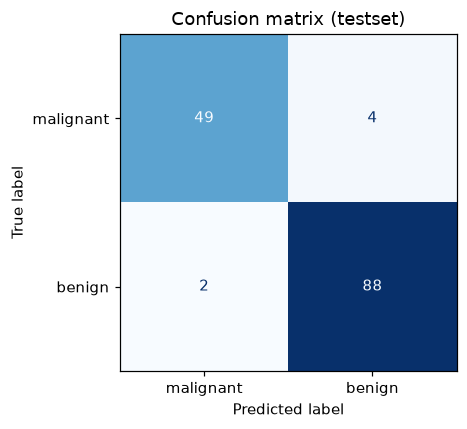

In [7]:
# Een confusion matrix maakt concreet WELKE fouten het model maakt.
# In een medische context is de rechterbovenhoek (kwaadaardig gemist!)
# veel erger dan de linkeronderhoek.
fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=class_names, cmap="Blues", colorbar=False, ax=ax
)
ax.set_title("Confusion matrix (testset)")
plt.tight_layout()
plt.show()

In [8]:
# De predictie voor ONZE patiënt.
pred_label = model.predict(X_test.iloc[[i]])[0]
pred_proba = model.predict_proba(X_test.iloc[[i]])[0]

print(f"--- Patiënt {i} volgens het random forest ---")
print(f"Werkelijke diagnose : {class_names[y_test.iloc[i]]}")
print(f"Modelpredictie      : {class_names[pred_label]}")
print(f"Kans op 'benign'    : {pred_proba[1]:.4f}")
print(f"Kans op 'malignant' : {pred_proba[0]:.4f}")
print()
print("De vraag voor de rest van de notebook: WAAROM?")

--- Patiënt 7 volgens het random forest ---
Werkelijke diagnose : malignant
Modelpredictie      : malignant
Kans op 'benign'    : 0.0579
Kans op 'malignant' : 0.9421

De vraag voor de rest van de notebook: WAAROM?


### 2.1 Eerste (naïeve) poging: de ingebouwde feature importance

`model.feature_importances_` geeft de **mean decrease in impurity** (MDI): hoeveel elke feature
gemiddeld bijdroeg aan het "zuiverder" maken van de splits in de bomen.

Dat is gratis meegeleverd, maar het heeft drie serieuze problemen:

1. **Bias richting features met veel unieke waarden** — continue features winnen bijna altijd van binaire.
2. **Berekend op de trainingsdata** — een feature die het model laat overfitten lijkt belangrijk.
3. **Alleen globaal en zonder richting** — je weet niet of een hoge waarde de predictie *omhoog* of *omlaag* duwt, en al helemaal niet wat er bij één patiënt gebeurde.

Er bestaat een eenvoudiger en eerlijker alternatief: **permutation importance**.

### 2.2 Permutation importance: kapotmaken en kijken wat je mist

Het idee is verrassend simpel. Wil je weten hoe belangrijk een feature is?
**Maak hem onbruikbaar en kijk hoeveel slechter het model wordt.**

Concreet, voor bijvoorbeeld `mean radius`:

1. Neem de testset.
2. **Schud die ene kolom willekeurig door elkaar.** Elke patiënt krijgt nu de straal van een
   *willekeurige andere* patiënt. Alle andere kolommen blijven kloppen.
3. Laat het model opnieuw voorspellen en kijk hoeveel accuracy je verliest.

```
        origineel                      na het schudden van 'radius'
   ┌────────┬─────────┬───────┐    ┌────────┬─────────┬───────┐
   │ radius │ texture │ echt  │    │ radius │ texture │ echt  │
   ├────────┼─────────┼───────┤    ├────────┼─────────┼───────┤
   │  17.9  │  10.4   │  ✗    │    │  12.4  │  10.4   │  ✗    │  ← straal van
   │  20.6  │  17.8   │  ✗    │    │  17.9  │  17.8   │  ✗    │     iemand anders
   │  12.4  │  15.7   │  ✓    │    │  20.6  │  15.7   │  ✓    │
   └────────┴─────────┴───────┘    └────────┴─────────┴───────┘
     kolom hoort bij de patiënt      kolom is losgekoppeld van de patiënt
```

De uitkomst laat zich lezen als een gemis:

- **Zakt de score?** Dan leunde het model op die feature.
- **Verandert er niets?** Dan deed die feature niets — het model kan perfect zonder.

Herhaal dat kolom per kolom en je hebt een ranglijst. Drie redenen waarom dit beter is dan MDI:

| | Waarom het helpt |
|---|---|
| Het gebeurt op de **testdata** | Je meet wat de feature waard is voor *nieuwe* patiënten, niet hoe vaak het model hem tijdens het trainen toevallig gebruikte. |
| Het model wordt **niet hertraind** | Je meet dit model, zoals het nu is. Snel, en geen toeval van een nieuwe training erbij. |
| Het werkt op **elk** model | Random forest, neuraal netwerk, black box van een leverancier — je hebt alleen voorspellingen nodig. |

> **Waarom schudden en niet gewoon de kolom weglaten?** Omdat het model 30 kolommen verwacht.
> Door te schudden houd je de vorm én de verdeling van de data intact — alleen het *verband*
> met de patiënt is kapot. Dat is precies wat je wil meten.
>
> En omdat het schudden toeval is, herhaal je het een paar keer (`n_repeats`) en neem je het
> gemiddelde.

We meten de schade hieronder met de **AUC** in plaats van de accuracy. Reden: accuracy telt
alleen hoeveel patiënten van kant wisselen, en dat zijn er in een testset van 143 al snel nul
of één. AUC kijkt naar de voorspelde kansen zelf en is dus veel gevoeliger voor kleine schade.

In [9]:
# Laten we het één keer met de hand doen, voor twee kolommen: eentje waarvan we
# vermoeden dat het model erop leunt, en eentje die er waarschijnlijk niet toe doet.
def schud_en_meet(kolom):
    X_geschud = X_test.copy()
    rng = np.random.default_rng(RANDOM_STATE)               # zelfde toeval voor elke kolom
    X_geschud[kolom] = rng.permutation(X_geschud[kolom].values)
    return roc_auc_score(y_test, model.predict_proba(X_geschud)[:, 1])

basis_auc = roc_auc_score(y_test, model.predict_proba(X_test)[:, 1])
print(f"AUC met correcte data: {basis_auc:.4f}")
print()

for kolom in ["worst concave points", "fractal dimension error"]:
    auc = schud_en_meet(kolom)
    print(f"  {kolom:24s} geschud -> AUC {auc:.4f}   verlies {basis_auc - auc:+.4f}")

print()
print("Dat verlies IS de permutation importance van die kolom.")
print("De ene feature wordt gemist, de andere helemaal niet.")

AUC met correcte data: 0.9939

  worst concave points     geschud -> AUC 0.9889   verlies +0.0050


  fractal dimension error  geschud -> AUC 0.9939   verlies +0.0000

Dat verlies IS de permutation importance van die kolom.
De ene feature wordt gemist, de andere helemaal niet.


**Kijk goed naar de grootte van dat verlies: het is klein.** Dat is geen fout, en het is
belangrijk om te bespreken.

De reden: `worst radius`, `worst perimeter` en `worst area` meten alledrie in feite hoe *groot*
de tumor is. Schud je er één door elkaar, dan pakt het bos gewoon een van de andere twee als
vervanger. Elke feature lijkt daardoor afzonderlijk misbaar, terwijl de *groep* samen
cruciaal is.

Dit is de bekendste beperking van permutation importance, en je komt hem straks bij SHAP
opnieuw tegen: **sterk gecorreleerde features verdelen hun belang onder elkaar.**
Wil je weten hoe belangrijk "tumorgrootte" is, schud dan die kolommen samen.

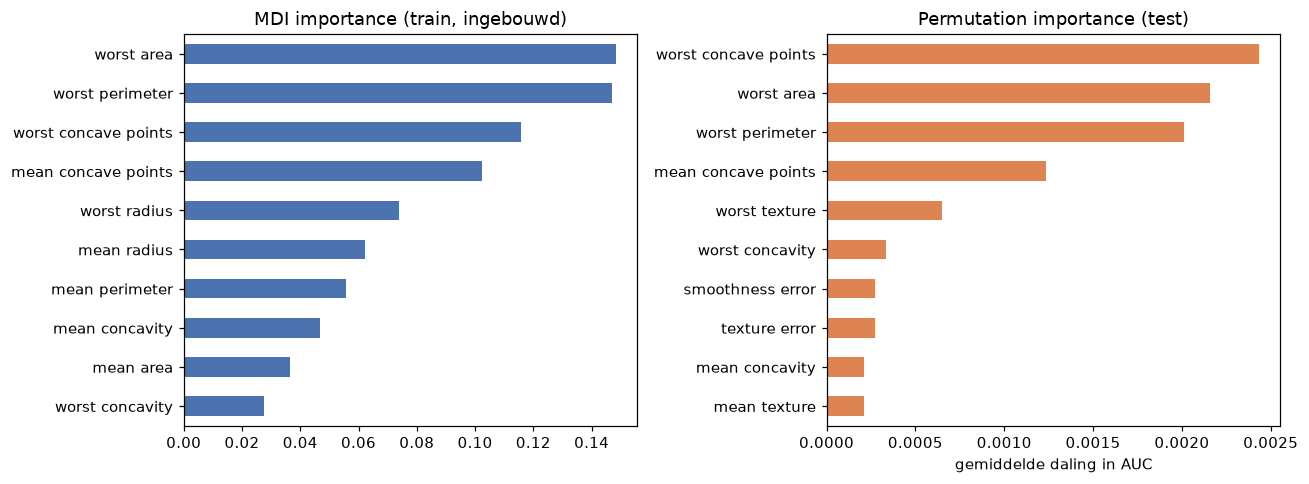

In [10]:
# --- (a) MDI importance: gratis, maar op de TRAINdata en zonder richting ---
mdi = pd.Series(model.feature_importances_, index=feature_names).sort_values(ascending=False)

# --- (b) Permutation importance op de TESTdata: eerlijker ---
# We hussellen elke kolom 10x en meten het gemiddelde verlies aan accuracy.
perm = permutation_importance(
    model, X_test, y_test,
    n_repeats=10,               # 10 keer schudden per kolom, om het toeval uit te middelen
    scoring="roc_auc",          # zelfde gevoelige maat als in de handmatige demo hierboven
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
perm_s = pd.Series(perm.importances_mean, index=feature_names).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
mdi.head(10)[::-1].plot.barh(ax=axes[0], color="#4C72B0")
axes[0].set_title("MDI importance (train, ingebouwd)")
perm_s.head(10)[::-1].plot.barh(ax=axes[1], color="#DD8452")
axes[1].set_title("Permutation importance (test)")
axes[1].set_xlabel("gemiddelde daling in AUC")
plt.tight_layout()
plt.show()

**Observatie voor de klas:** de twee ranglijsten verschillen. Sterk gecorreleerde features
(`mean radius`, `mean perimeter` en `mean area` meten in feite hetzelfde) delen hun belang
en duiken op wisselende plaatsen op.

Maar het grootste bezwaar blijft: dit zegt **niets over patiënt 7**.
Daarvoor hebben we lokale uitleg nodig.

---

# 🟢 Methode 1 — SHAP

## 3.1 Het idee

SHAP staat voor **SHapley Additive exPlanations** (Lundberg & Lee, 2017). Het leent een idee uit
de coöperatieve speltheorie van Lloyd Shapley.

### Het spel

Stel je voor dat de **features samen een spel spelen** en dat de "winst" de predictie is.
De vraag: *hoe verdeel je die winst eerlijk over de spelers?*

De **SHAP-waarde** van een feature is zijn gemiddelde bijdrage over **alle mogelijke volgordes**
waarin je de features aan het model kunt toevoegen. In gewone taal:

> *"Wat verandert er aan de predictie als het model deze ene feature erbij krijgt — gemiddeld
> over alle groepen features die het al zou kunnen kennen?"*

Het resultaat is per feature één getal, dat zegt **hoeveel die featurewaarde de predictie
wegduwde van het gemiddelde**, voor deze ene rij.

### Waarom die verdeling "eerlijk" heet

De manier waarop SHAP de winst verdeelt, heeft precies de eigenschappen die je intuïtief zou
eisen van een eerlijke verdeling:

- Twee features die altijd hetzelfde doen, krijgen dezelfde waarde.
- Een feature die de predictie nooit verandert, krijgt nul.
- De bijdragen samen brengen je van de gemiddelde voorspelling naar de voorspelling voor
  deze patiënt — dat is precies wat de waterfall plot in §3.4 uittekent.

Shapley bewees dat er maar **één** manier van verdelen bestaat die dat alledrie tegelijk doet.
Dat is de reden dat SHAP als de theoretisch correcte methode geldt.

### De prijs: rekenkracht

Al die groepen features doorlopen zijn er bij 30 features ruim een miljard.
Daarom bestaan er *explainers* die dit benaderen of exact-maar-snel uitrekenen:

| Explainer | Voor welk model | Snelheid |
|---|---|---|
| `TreeExplainer` | bomen, random forest, XGBoost, LightGBM | exact & snel |
| `LinearExplainer` | lineaire modellen | triviaal |
| `KernelExplainer` | **elk** model (model-agnostisch) | traag, benadering |
| `DeepExplainer` / `GradientExplainer` | neurale netwerken | middelmatig |

Wij hebben een random forest → `TreeExplainer`. 🎉

> **Misverstand om weg te nemen:** een SHAP-waarde is **geen** causaal effect en
> **geen** "hoe belangrijk is deze feature". Het is: *hoeveel duwde deze featurewaarde de
> predictie weg van het gemiddelde, voor deze ene rij.*

## 3.2 De explainer opzetten

In [11]:
# De explainer krijgt het GETRAINDE model. Voor bomen heeft hij geen
# achtergronddataset nodig: de boomstructuur bevat al alle informatie
# over hoe vaak welke paden gevolgd worden.
explainer = shap.TreeExplainer(model)

# De explainer aanroepen op data geeft een 'Explanation'-object terug.
# Dat bundelt drie dingen: de SHAP-waarden, de originele featurewaarden
# en de base value. Alle shap.plots.* functies kunnen daar meteen mee overweg.
shap_exp = explainer(X_test)

print("Type          :", type(shap_exp).__name__)
print("values.shape  :", shap_exp.values.shape)
print()
print("Lees dat als (aantal rijen, aantal features, aantal klassen).")

Type          : Explanation
values.shape  : (143, 30, 2)

Lees dat als (aantal rijen, aantal features, aantal klassen).


### Even opletten: de derde dimensie

Voor een **binaire classifier** geeft `TreeExplainer` waarden voor *beide* klassen:
shape `(n_rijen, 30 features, 2 klassen)`. De twee lagen zijn elkaars spiegelbeeld
(ze tellen samen op tot 0), want de kansen tellen op tot 1.

We kiezen consequent **klasse 1 = `benign` (goedaardig)** — ook bij LIME straks.
Een **positieve** waarde betekent dan: *deze featurewaarde duwt de predictie richting "goedaardig"*.
Een **negatieve** waarde duwt richting "kwaadaardig".

In [12]:
# Slice de laatste as: alle rijen, alle features, klasse-index 1.
shap_benign = shap_exp[:, :, 1]

print("Vorm na slicing :", shap_benign.values.shape)
print(f"Base value      : {shap_benign.base_values[0]:.4f}")
print()
print("De base value is de gemiddelde voorspelling van het model over de trainingsdata:")
print(f"  aandeel 'benign' in de trainset = {y_train.mean():.4f}")
print("Dat is het VERTREKPUNT van elke uitleg: zonder enige feature te kennen,")
print("zou het model deze kans voorspellen.")

Vorm na slicing : (143, 30)
Base value      : 0.6260

De base value is de gemiddelde voorspelling van het model over de trainingsdata:
  aandeel 'benign' in de trainset = 0.6268
Dat is het VERTREKPUNT van elke uitleg: zonder enige feature te kennen,
zou het model deze kans voorspellen.


## 3.3 Globale uitleg — SHAP-waarden aggregeren

Een SHAP-waarde is lokaal, maar als je per feature het **gemiddelde van de absolute waarden**
neemt over alle testrijen, krijg je een globale importance die wél consistent is. Grote
bijdragen tellen dan mee, of ze nu naar links of naar rechts duwden.

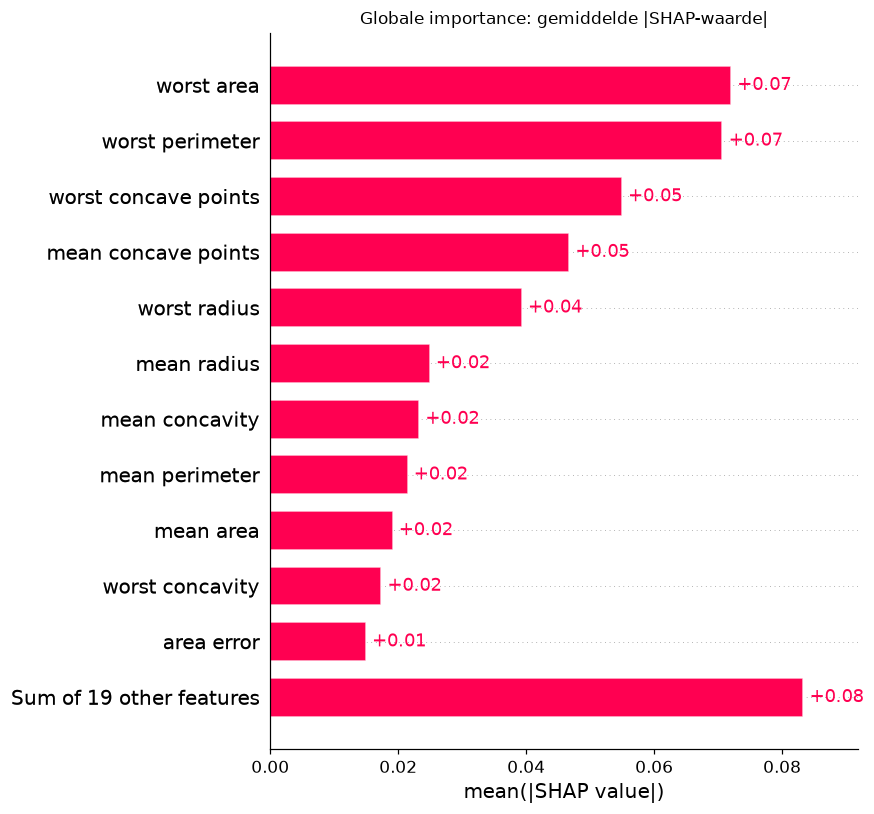

In [13]:
# De bar plot doet precies die aggregatie: gemiddelde |SHAP| per feature.
shap.plots.bar(shap_benign, max_display=12, show=False)
plt.title("Globale importance: gemiddelde |SHAP-waarde|", fontsize=11)
plt.tight_layout()
plt.show()

**Te bespreken in de les:** bovenaan staan `worst concave points`, `worst perimeter` en
`worst area` — allemaal maten voor hoe groot en hoe grillig gevormd de tumor is. Medisch gezien
klopt dat: grote tumoren met veel concave randen zijn verdachter. Het model heeft dus iets
geleerd dat een patholoog herkent.

Dat is precies het soort *sanity check* waarvoor je XAI gebruikt. Had hier een administratief
veld bovenaan gestaan — een patiëntnummer, een labcode — dan wist je meteen dat er iets mis was
met je data.

## 3.4 Lokale uitleg — patiënt 7 ontleed

### De waterfall plot

Dit is *de* plot om aan een niet-technisch publiek te tonen. Je leest hem van onder naar boven:

- Onderaan start je bij de **base value**: de gemiddelde voorspelling van het model, dus wat
  het zou gokken zonder ook maar één feature te kennen.
- Elke balk is één feature die de predictie verschuift (rood = omhoog duwen, blauw = omlaag).
- Bovenaan kom je uit bij de uiteindelijke voorspelde kans voor **deze** patiënt.

De features die het minst bijdragen worden onderaan samengevat als "n other features".

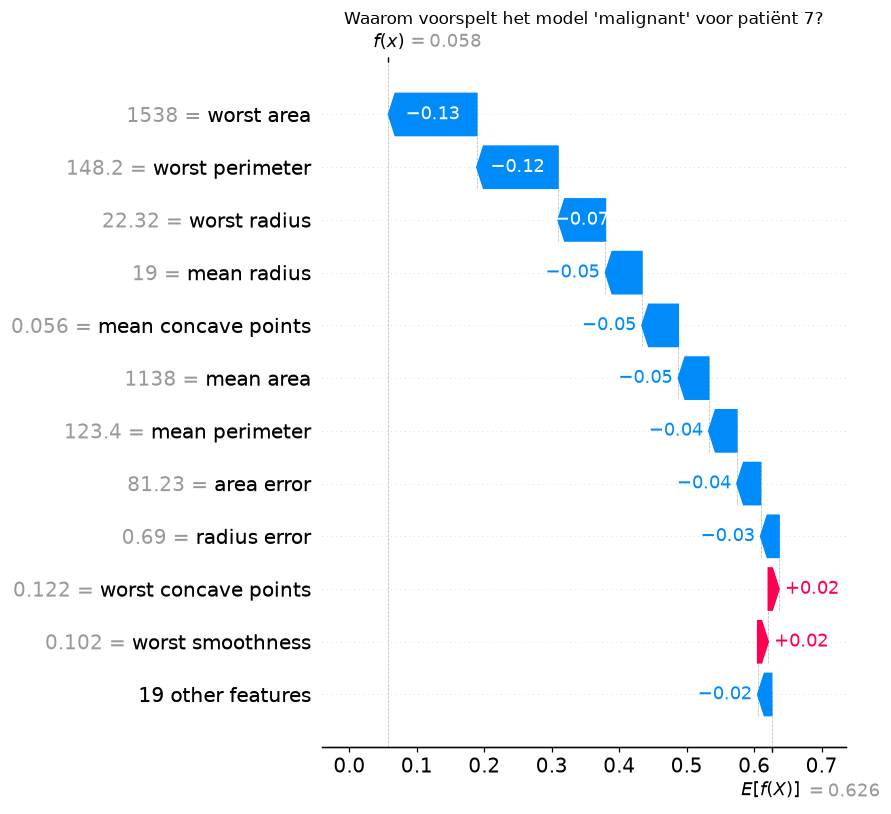

In [14]:
# shap_benign[i] selecteert de uitleg van één rij -> een Explanation van 1 instantie.
shap.plots.waterfall(shap_benign[i], max_display=12, show=False)
plt.title(f"Waarom voorspelt het model '{class_names[pred_label]}' voor patiënt {i}?",
          fontsize=11)
plt.tight_layout()
plt.show()

In [15]:
# Dezelfde informatie als een leesbare tabel: de 10 sterkste bijdragen,
# gesorteerd op absolute grootte. Dit is vaak nuttiger dan een plot
# als je de uitleg in een rapport of een applicatie moet gieten.
shap_tabel = (
    pd.DataFrame({
        "featurewaarde": X_test.iloc[i].values,
        "shap_waarde": shap_benign.values[i],
    }, index=feature_names)
    .assign(richting=lambda d: np.where(d.shap_waarde > 0, "-> benign", "-> malignant"))
    .reindex(pd.Series(np.abs(shap_benign.values[i]), index=feature_names)
             .sort_values(ascending=False).index)
    .head(10)
    .round(4)
)
display(shap_tabel)

,featurewaarde,shap_waarde,richting
worst area,1538.0000,-0.1309,-> malignant
worst perimeter,148.2000,-0.1204,-> malignant
worst radius,22.3200,-0.0703,-> malignant
mean radius,19.0000,-0.0541,-> malignant
mean concave points,0.0563,-0.0539,-> malignant
mean area,1138.0000,-0.0451,-> malignant
mean perimeter,123.4000,-0.0417,-> malignant
area error,81.2300,-0.0351,-> malignant
radius error,0.6896,-0.0274,-> malignant
worst concave points,0.1218,0.0160,-> benign


### De force plot: dezelfde uitleg, horizontaal

De force plot toont de bijdragen als krachten die tegen elkaar in duwen. Handig als je
meerdere patiënten naast elkaar wil tonen.

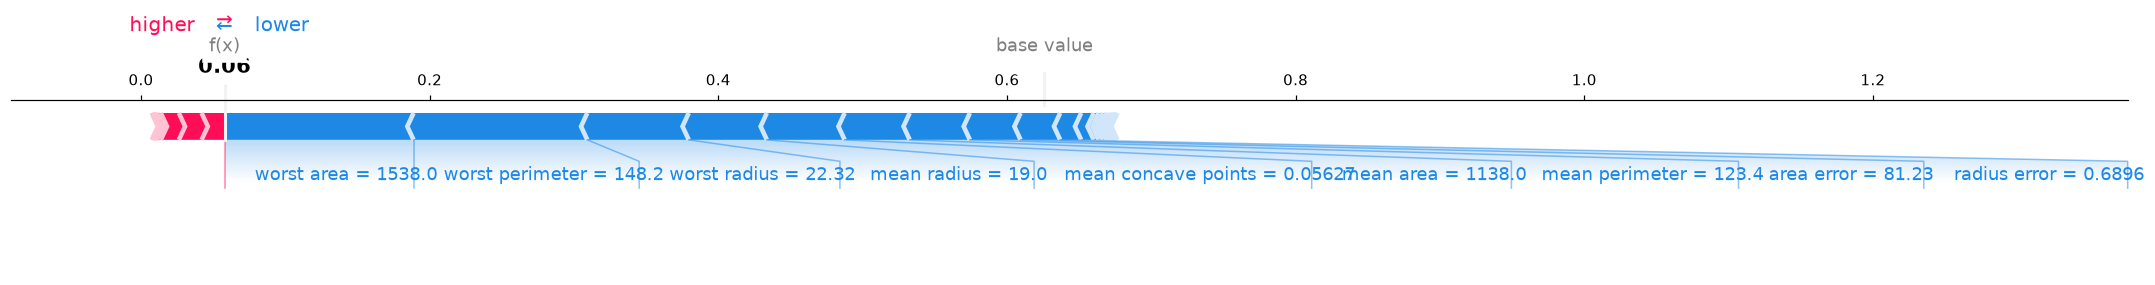

In [16]:
# matplotlib=True rendert een statische figuur. (Zonder die parameter krijg je
# een interactieve JavaScript-versie; die vereist shap.initjs() en werkt niet
# in elke notebook-viewer, dus voor lesmateriaal is de statische versie veiliger.)
shap.plots.force(shap_benign[i], matplotlib=True, show=False, figsize=(20, 3))
plt.tight_layout()
plt.show()

# 🟠 Methode 2 — LIME

## 4.1 Het idee

LIME = **Local Interpretable Model-agnostic Explanations** (Ribeiro, Singh & Guestrin, 2016).

> *Een complexe beslissingsgrens is globaal krom, maar als je ver genoeg inzoomt op één punt,
> is hij bijna recht.*

Dus: benader het black-box model **in de buurt van één instantie** met een simpel,
leesbaar model (meestal een lineaire regressie). De coëfficiënten van dat simpele model
zijn je uitleg.

Dat klinkt abstract, dus laten we het eerst tekenen.

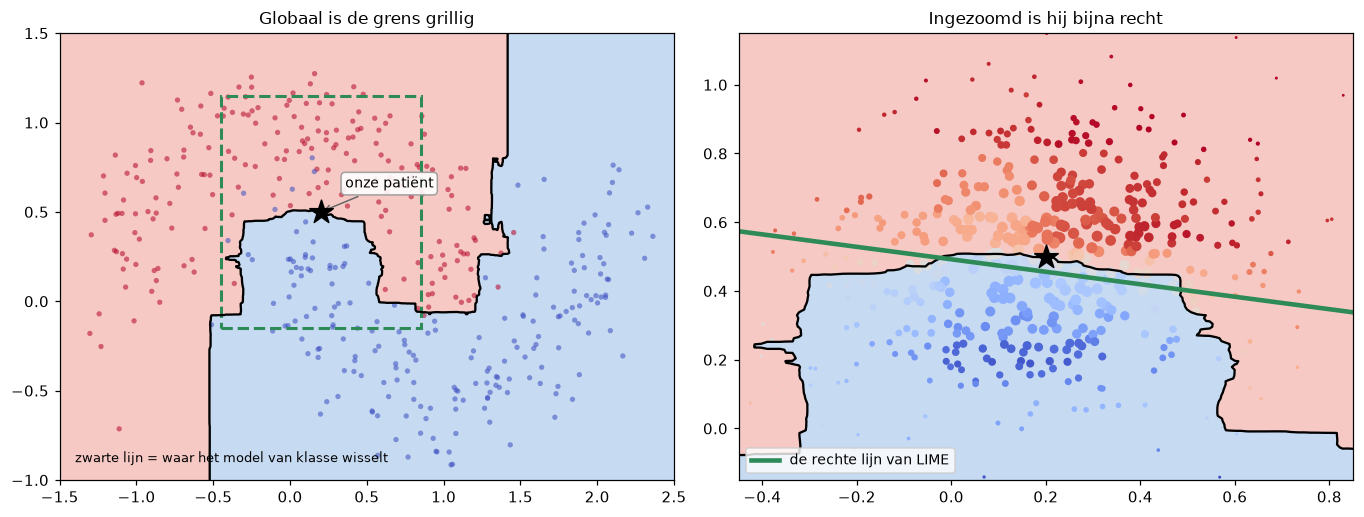

De rechte lijn geeft 90% van de nepatiënten hetzelfde oordeel als het bos.
In de buurt van deze patiënt is één rechte lijn dus een prima vervanger
voor een model van 200 beslisbomen. Dat is de hele truc van LIME.


In [17]:
# Een tekening met twee features, zodat we de beslissingsgrens kunnen zién.
# We gebruiken hier even een ander speelgoedmodel, puur om het idee te tonen.
from sklearn.datasets import make_moons
from sklearn.linear_model import LogisticRegression

# --- een black-box model met een bewust grillige grens ---
X_speel, y_speel = make_moons(n_samples=400, noise=0.2, random_state=RANDOM_STATE)
bos_speel = RandomForestClassifier(n_estimators=200, min_samples_leaf=5,
                                   random_state=RANDOM_STATE).fit(X_speel, y_speel)

onze_patient = np.array([0.20, 0.50])    # de rij die we willen verklaren
buurt        = 0.25                      # hoe groot we "de buurt" maken

# --- stap 1 en 2: nepatiënten maken en door het model laten beoordelen ---
rng_zoom = np.random.default_rng(RANDOM_STATE)
nepatienten = rng_zoom.normal(onze_patient, buurt, size=(500, 2))
oordeel     = bos_speel.predict_proba(nepatienten)[:, 1]

# --- stap 3: wegen naar afstand (zie hierboven) ---
afstand   = np.linalg.norm(nepatienten - onze_patient, axis=1)
gewichten = np.exp(-(afstand / buurt) ** 2 / 2)

# --- stap 4: één rechte lijn door die gewogen nepatiënten ---
lokaal = LogisticRegression().fit(nepatienten, (oordeel > 0.5).astype(int),
                                  sample_weight=gewichten)

# ---------- tekenen ----------
xx, yy = np.meshgrid(np.linspace(-1.5, 2.5, 300), np.linspace(-1.0, 1.5, 300))
zz = bos_speel.predict_proba(np.c_[xx.ravel(), yy.ravel()])[:, 1].reshape(xx.shape)

fig, (links, rechts) = plt.subplots(1, 2, figsize=(12.5, 4.8))

for ax in (links, rechts):
    ax.contourf(xx, yy, zz, levels=[0, 0.5, 1], colors=["#F6C9C5", "#C6DAF2"])
    ax.contour(xx, yy, zz, levels=[0.5], colors="black", linewidths=1.5)

# ---- links: het hele plaatje ----
links.scatter(X_speel[:, 0], X_speel[:, 1], c=y_speel, cmap="coolwarm_r",
              s=12, edgecolor="none", alpha=0.55)
kader = plt.Rectangle(onze_patient - 2.6 * buurt, 5.2 * buurt, 5.2 * buurt,
                      fill=False, ec="#2E8B57", lw=2, ls="--")
links.add_patch(kader)
links.set_title("Globaal is de grens grillig", fontsize=11)
links.text(-1.4, -0.9, "zwarte lijn = waar het model van klasse wisselt", fontsize=8.5)

# ---- rechts: ingezoomd op het groene kader ----
rechts.scatter(nepatienten[:, 0], nepatienten[:, 1], s=gewichten * 55 + 3,
               c=oordeel, cmap="coolwarm_r", vmin=0, vmax=1, edgecolor="none")
x_lijn = np.linspace(onze_patient[0] - 3 * buurt, onze_patient[0] + 3 * buurt, 10)
w, b = lokaal.coef_[0], lokaal.intercept_[0]
rechts.plot(x_lijn, -(w[0] * x_lijn + b) / w[1], color="#2E8B57", lw=3,
            label="de rechte lijn van LIME")
rechts.set_xlim(onze_patient[0] - 2.6 * buurt, onze_patient[0] + 2.6 * buurt)
rechts.set_ylim(onze_patient[1] - 2.6 * buurt, onze_patient[1] + 2.6 * buurt)
rechts.set_title("Ingezoomd is hij bijna recht", fontsize=11)
rechts.legend(fontsize=9, loc="lower left")

for ax in (links, rechts):
    ax.scatter(*onze_patient, s=260, marker="*", color="black", zorder=6)
links.annotate("onze patiënt", onze_patient, textcoords="offset points",
               xytext=(16, 16), fontsize=9,
               bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="0.6", alpha=0.9),
               arrowprops=dict(arrowstyle="->", color="0.4"))

plt.tight_layout()
plt.show()

trouw = np.average(lokaal.predict(nepatienten) == (oordeel > 0.5), weights=gewichten)
print(f"De rechte lijn geeft {trouw:.0%} van de nepatiënten hetzelfde oordeel als het bos.")
print("In de buurt van deze patiënt is één rechte lijn dus een prima vervanger")
print("voor een model van 200 beslisbomen. Dat is de hele truc van LIME.")

Links zie je waarom je dit niet globaal kunt doen: die grens is met geen mogelijkheid door één
rechte lijn te beschrijven. Rechts, binnen het groene kader, lukt het moeiteloos.

Let ook op de grootte van de stippen. De nepatiënten vlakbij onze patiënt zijn groot: die
bepalen waar de lijn komt te liggen. Die aan de rand zijn klein en duwen nauwelijks mee.
Waarom dat zo werkt, staat hieronder bij stap 4.

> Het lukt niet overal even goed. Was onze patiënt in een scherpe bocht van de grens beland, dan
> had geen enkele rechte lijn gepast. Hoe goed het gelukt is, kun je gelukkig aflezen — daar
> gaat §4.5 over.

### Het recept, stap voor stap

1. Neem de rij die je wil verklaren.
2. **Genereer perturbaties**: duizenden nieuwe, licht gewijzigde rijen eromheen
   (LIME sampelt uit de verdeling van de trainingsdata).
3. **Label ze met het black-box model**: vraag aan het echte model wat het voorspelt
   voor elke perturbatie. *Het model wordt hier als orakel gebruikt — vandaar
   "model-agnostisch": LIME hoeft niet te weten wat erin zit.*
4. **Weeg** elke perturbatie op basis van hoe dicht ze bij de originele rij ligt:
   dichtbij telt zwaar, veraf telt licht.
5. **Train een gewogen lineaire regressie** op die gelabelde perturbaties.
6. De **coëfficiënten** van dat lineaire model zijn de uitleg.

LIME zoekt daarbij een simpel model dat twee dingen tegelijk moet doen: **lokaal goed lijken op
het black-box model**, én **kort genoeg blijven om leesbaar te zijn**. Dat laatste bepaal je zelf
met `num_features`.

### Wat betekent "gewogen"?

Stap 4 en 5 doen het echte werk, dus daar staan we even bij stil.

Bij een **gewone** regressie telt elk punt even zwaar mee: alle punten trekken met dezelfde
kracht aan de lijn. Bij een **gewogen** regressie geef je elk punt een gewicht. Punten met een
hoog gewicht trekken hard aan de lijn, punten met een laag gewicht nauwelijks.

LIME gebruikt dat om de uitleg *lokaal* te houden. Zijn verzonnen patiënten liggen namelijk niet
allemaal even dicht bij de onze: sommige verschillen in één detail, andere in bijna alles. Zou
je ze allemaal even zwaar laten meetellen, dan wordt de lijn vooral bepaald door de verre
nepatiënten — en dan krijg je een uitleg over de hele dataset in plaats van over déze patiënt.

De regel is dus simpel: **hoe dichter een nepatiënt bij de onze ligt, hoe zwaarder hij meetelt.**

Technisch is er weinig magie aan: LIME berekent per nepatiënt de afstand tot de onze, zet die met
de klokcurve om in een getal tussen 0 en 1, en geeft dat rijtje mee als `sample_weight` aan de
ridge-regressie van scikit-learn. De breedte van de klok is standaard
`sqrt(aantal features) * 0.75` — bij onze 30 features dus ongeveer 4.1. Je kunt hem zelf zetten
met `kernel_width` als je de buurt smaller of breder wil maken.


### Nog één ding: LIME maakt er ja/nee-vragen van

Voor tabulaire data zet LIME elke continue feature eerst om in een **ja/nee-vraag met een
drempel**: niet "hoeveel mm² is deze tumor?", maar "is de oppervlakte groter dan 1034?".
De uitleg bestaat daardoor uit regels in plaats van kale getallen. Waarom dat handig is — en
hoe je zo'n regel leest — zie je het beste zodra we de eerste echte uitleg op het scherm hebben.

> **Belangrijkste verschil met SHAP:** LIME geeft je geen enkele zekerheid dat de uitleg klopt.
> Wat je wél krijgt is een R², die meet hoe goed de rechte lijn het model in de buurt van deze
> patiënt benadert. Die R² is dus een **kwaliteitscontrole op de uitleg zelf** — en je moet er
> altijd naar kijken (§4.5).

## 4.2 De explainer opzetten

In [18]:
# De LIME-explainer wordt gebouwd op de TRAININGSDATA. Hij heeft die nodig om
# te weten hoe hij realistische perturbaties moet genereren (gemiddelde en
# standaardafwijking per feature, en de kwartielgrenzen voor de discretisatie).
lime_explainer = lime.lime_tabular.LimeTabularExplainer(
    training_data=X_train.values,        # LIME wil numpy, geen DataFrame
    feature_names=feature_names,         # zodat de uitleg leesbaar is
    class_names=class_names,             # ['malignant', 'benign']
    mode="classification",
    discretize_continuous=True,          # -> regels i.p.v. kale getallen (zie hierboven)
    random_state=RANDOM_STATE,           # LIME is stochastisch: seed = reproduceerbaar
)

# LIME roept ons model aan met een kale numpy-array, terwijl het model getraind is
# op een DataFrame MET kolomnamen. Zonder dit wrappertje krijg je bij elke aanroep
# een sklearn-waarschuwing. Meteen een goede gewoonte: maak de predict-functie
# expliciet in plaats van model.predict_proba rechtstreeks door te geven.
def voorspel_kans(rijen):
    return model.predict_proba(pd.DataFrame(rijen, columns=feature_names))

print("LIME-explainer klaar.")
print(f"Gebouwd op {X_train.shape[0]} trainingsrijen en {len(feature_names)} features.")

LIME-explainer klaar.
Gebouwd op 426 trainingsrijen en 30 features.


## 4.3 Lokale uitleg — patiënt 7 ontleed

In [19]:
# Nu verklaren we DEZELFDE patiënt i als bij SHAP.
#
# Belangrijke parameters:
#   data_row      : de instantie die je wil verklaren (1D numpy array)
#   predict_fn    : een functie die KANSEN teruggeeft (niet model.predict!) ->
#                   LIME heeft een continue output nodig om op te regresseren
#   num_features  : hoeveel features mag de uitleg bevatten (de Omega-strafterm)
#   num_samples   : hoeveel perturbaties genereren. Meer = stabieler maar trager.
#   labels        : voor welke klasse(n) we uitleg willen -> (1,) = 'benign'
lime_exp = lime_explainer.explain_instance(
    data_row=X_test.iloc[i].values,
    predict_fn=voorspel_kans,
    num_features=10,
    num_samples=5000,
    labels=(1,),
)

print(f"Uitleg gegenereerd voor patiënt {i}, richting klasse '{class_names[1]}'.")

Uitleg gegenereerd voor patiënt 7, richting klasse 'benign'.


In [20]:
# as_list() geeft de uitleg als (regel, gewicht)-paren.
# Positief gewicht = duwt richting 'benign' (klasse 1), negatief = richting 'malignant'.
print(f"LIME-uitleg voor patiënt {i} — richting klasse '{class_names[1]}':")
print()
for regel, gewicht in lime_exp.as_list(label=1):
    pijl = "-> benign   " if gewicht > 0 else "-> malignant"
    print(f"  {gewicht:+7.4f}  {pijl}  {regel}")

LIME-uitleg voor patiënt 7 — richting klasse 'benign':

  -0.1489  -> malignant  worst area > 1034.25
  -0.1267  -> malignant  worst perimeter > 124.97
  -0.0975  -> malignant  worst radius > 18.55
  -0.0485  -> malignant  mean area > 765.38
  -0.0454  -> malignant  area error > 45.13
  -0.0364  -> malignant  mean radius > 15.75
  -0.0277  -> malignant  mean perimeter > 103.67
  -0.0276  -> malignant  radius error > 0.47
  +0.0202  -> benign     worst smoothness <= 0.12
  +0.0174  -> benign     mean smoothness <= 0.09


### Zo lees je één zo'n regel

De uitleg bestaat uit tien van die regels. We pakken de bovenste en halen hem uit elkaar:

```
     -0.1489        -> malignant        worst area > 1034.25
        │                  │                      │
        │                  │                      └─  de VRAAG die LIME stelde
        │                  └─────────────────────────  de RICHTING
        └────────────────────────────────────────────  hoe HARD het duwt
```

**Rechts: de vraag.** LIME vraagt niet "hoe groot is deze tumor?", maar "is de oppervlakte
groter dan 1034.25?" Bij patiënt 7 is het antwoord **ja**.

> Dat antwoord is trouwens altijd ja. Elke regel in de lijst is een beschrijving van *deze*
> patiënt — LIME laat je zien in welk hokje hij valt, niet in welke hokjes hij níét valt.

**Midden: de richting.** Het minteken betekent: weg van "goedaardig", dus richting kwaadaardig.
We verklaren immers de kans op `benign` (§3.2), dus alles wat negatief is, duwt naar de
andere klasse.

**Links: hoe hard.** Dat is het getal waar we zo naar kijken.

Alles bij elkaar leest die ene regel dus als één zin:

> *"Deze tumor is groter dan 1034,25 — en dat feit duwt de voorspelling met 0,1489 richting
> kwaadaardig."*

In [21]:
# Laten we die bovenste regel er even bij pakken en narekenen.
def kolom_uit_regel(regel):
    # Een regel als 'worst area > 1034.25' bevat de kolomnaam letterlijk.
    # De juiste naam is de langste die erin voorkomt ('worst area', niet 'area').
    treffers = [f for f in feature_names if f in regel]
    return max(treffers, key=len) if treffers else regel

regel, gewicht = lime_exp.as_list(label=1)[0]      # de sterkste regel
kolom = kolom_uit_regel(regel)

print(f"de regel     : {regel}")
print(f"de vraag     : valt '{kolom}' binnen dat bereik?")
print(f"deze patiënt : {X_test.iloc[i][kolom]:.2f}   ->  ja, daarom staat de regel in de lijst")
print(f"de richting  : {'naar benign (goedaardig)' if gewicht > 0 else 'naar malignant (kwaadaardig)'}")
print(f"hoe hard     : {abs(gewicht):.4f}")

de regel     : worst area > 1034.25
de vraag     : valt 'worst area' binnen dat bereik?
deze patiënt : 1538.00   ->  ja, daarom staat de regel in de lijst
de richting  : naar malignant (kwaadaardig)
hoe hard     : 0.1489


#### En waar komt dat laatste getal vandaan?

LIME neemt zijn duizenden nepatiënten en verdeelt ze in twee groepen:

| groep | wie zitten erin | gemiddelde kans op "goedaardig" |
|---|---|---|
| **ja** | grote tumor, net als onze patiënt (`> 1034`) | laag |
| **nee** | kleinere tumor (`<= 1034`) | hoger |

Het getal is simpelweg **het verschil tussen die twee groepen**:

> *"Nepatiënten met een grote tumor kregen van het model gemiddeld 0.15 minder kans op
> 'goedaardig' dan nepatiënten met een kleinere tumor."*

Dus geen helling, en geen "per mm²". Gewoon: hoeveel scheelt het of je in die groep zit of niet.

### Waarom een grens, en niet de exacte oppervlakte?

**Omdat het model zelf ook in grenzen denkt.** Een random forest vraagt nooit "hoeveel mm² is
deze tumor?", maar "meer of minder dan 1034?". Een regel volgt precies die manier van denken.

**En een regel zegt erbij waar deze patiënt staat.** `worst area > 1034.25` vertelt je meteen:
deze tumor zit in het grootste kwart. Bij `worst area: -0.068` weet je dat niet — je weet niet
eens of deze tumor groot of klein is.

> **De keerzijde:** iemand met 1035 en iemand met 2500 krijgen dezelfde regel én hetzelfde
> gewicht. En de grens van 1034 komt uit jouw trainingsdata: andere data, andere grens.

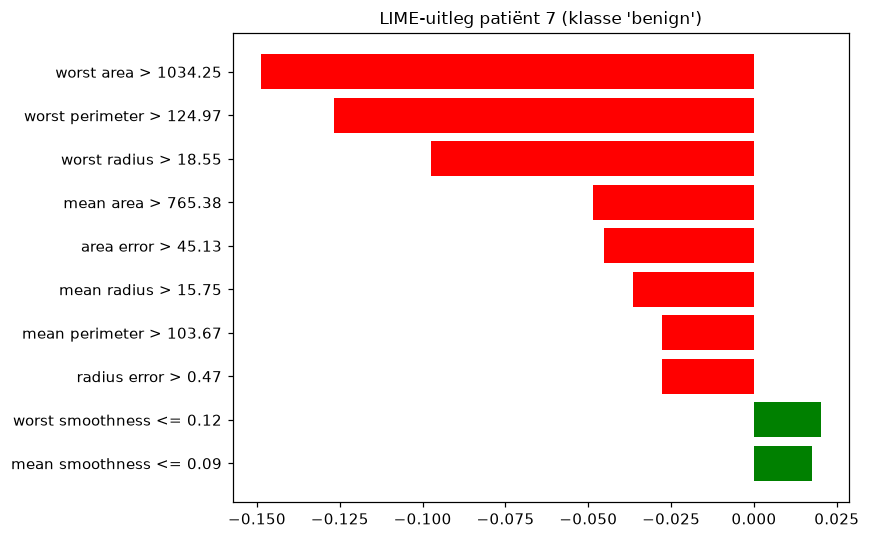

In [22]:
# LIME's eigen plotfunctie. Groen = richting de verklaarde klasse (benign),
# rood = ertegenin.
fig = lime_exp.as_pyplot_figure(label=1)
fig.set_size_inches(8, 5)
plt.title(f"LIME-uitleg patiënt {i} (klasse '{class_names[1]}')", fontsize=11)
plt.tight_layout()
plt.show()

In [25]:
# Die laatste optie is de enige aggregatie die verdedigbaar is: TELLEN, niet middelen.
# We hergebruiken kolom_uit_regel() uit §4.3 en kijken bij hoeveel van de 12
# patiënten een feature in de top vijf stond.
telling = pd.Series(
    [kolom_uit_regel(r) for uitleg in uitleg_per_patient.values() for r in uitleg]
).value_counts()

print("Bij hoeveel van de 12 patiënten stond deze feature in de top vijf?")
print()
print(telling.head(8).to_string())
print()
print("Let op: dit is een FREQUENTIE, geen belangrijkheid. Het zegt hoe vaak LIME een")
print("feature aanwees, niet hoe zwaar die woog. De namen bovenaan lijken op die uit de")
print("SHAP-ranglijst (§3.3), maar het zijn twee verschillende grootheden.")

Bij hoeveel van de 12 patiënten stond deze feature in de top vijf?

worst perimeter         10
worst area               9
worst radius             8
worst concave points     7
mean concave points      5
mean texture             4
mean radius              2
mean concavity           2

Let op: dit is een FREQUENTIE, geen belangrijkheid. Het zegt hoe vaak LIME een
feature aanwees, niet hoe zwaar die woog. De namen bovenaan lijken op die uit de
SHAP-ranglijst (§3.3), maar het zijn twee verschillende grootheden.


## 4.5 Hoe betrouwbaar is deze uitleg?

Bij LIME hoort één getal dat je altijd moet bekijken: de **R² van het lokale surrogaatmodel**.
Die zegt hoe goed de rechte lijn het echte model in de buurt van deze patiënt benadert.

Dit getal is minstens zo belangrijk als de uitleg zelf. **Is de R² laag, dan mag je de uitleg
niet vertrouwen** — het model is daar simpelweg te grillig om door een rechte lijn te worden
samengevat.

In [26]:
print(f"R² van het lokale surrogaat           : {lime_exp.score:.4f}")
print(f"Voorspelling van het lokale surrogaat : {lime_exp.local_pred[0]:.4f}")
print(f"Voorspelling van het ECHTE model      : {pred_proba[1]:.4f}")
print(f"Afwijking                             : {abs(lime_exp.local_pred[0] - pred_proba[1]):.4f}")
print()
print("Het surrogaat is dus een BENADERING van het model, geen kopie ervan.")
print("Hoe lager de R² en hoe groter de afwijking, hoe voorzichtiger je moet zijn")
print("met de uitleg die eruit rolt.")

R² van het lokale surrogaat           : 0.4797
Voorspelling van het lokale surrogaat : 0.1883
Voorspelling van het ECHTE model      : 0.0579
Afwijking                             : 0.1304

Het surrogaat is dus een BENADERING van het model, geen kopie ervan.
Hoe lager de R² en hoe groter de afwijking, hoe voorzichtiger je moet zijn
met de uitleg die eruit rolt.


**Interpretatie van dit resultaat:** de R² ligt hier rond de 0.5 en het surrogaat voorspelt een
merkbaar andere kans dan het echte model. Dat is géén fout in de code — het is een **eerlijk
signaal** dat het random forest rond deze patiënt sterk niet-lineair is. Een bos is opgebouwd
uit harde drempels ("is `worst area` groter dan 1034?"), en zo'n trappenlandschap laat zich nu
eenmaal slecht samenvatten met één rechte lijn. De *richting* van de uitleg blijft bruikbaar,
de *exacte getallen* niet.

Dit is precies het soort nuance dat studenten moeten meenemen: een uitlegmethode die altijd
een mooi plaatje produceert, produceert niet altijd een geldige uitleg.

### LIME is stochastisch — laat dat zien

SHAP geeft bij bomen altijd exact hetzelfde antwoord. LIME niet: het trekt willekeurige
perturbaties, dus twee runs geven licht verschillende gewichten. Dat is geen bug, dat is
de methode. Maar je studenten moeten dat weten vóór ze een LIME-uitleg aan een klant tonen.

We draaien de uitleg drie keer **zonder vaste seed** en vergelijken.

In [27]:
# Een nieuwe explainer ZONDER random_state, zodat elke run anders sampelt.
onstabiel = lime.lime_tabular.LimeTabularExplainer(
    training_data=X_train.values,
    feature_names=feature_names,
    class_names=class_names,
    mode="classification",
    discretize_continuous=True,
)

runs = {}
for r in range(3):
    e = onstabiel.explain_instance(
        X_test.iloc[i].values, voorspel_kans,
        num_features=8,
        num_samples=1000,   # bewust weinig samples -> meer ruis
        labels=(1,),
    )
    runs[f"run {r+1}"] = dict(e.as_list(label=1))

vergelijk = pd.DataFrame(runs).round(4)
print("Zelfde patiënt, drie LIME-runs met num_samples=1000:")
display(vergelijk)
print("Merk op: de gewichten verschillen, en soms verschijnt/verdwijnt een regel volledig.")
print("Verhoog num_samples (bv. 5000) en zet random_state -> veel stabieler.")

Zelfde patiënt, drie LIME-runs met num_samples=1000:


,run 1,run 2,run 3
worst area > 1034.25,-0.1388,-0.1503,-0.1528
worst perimeter > 124.97,-0.1300,-0.1268,-0.1309
worst radius > 18.55,-0.0975,-0.0867,-0.0816
mean area > 765.38,-0.0610,-0.0538,-0.0662
area error > 45.13,-0.0414,-0.0371,-0.0305
mean radius > 15.75,-0.0374,-0.0403,-0.0392
mean perimeter > 103.67,-0.0294,-0.0276,-0.0294
perimeter error > 3.28,-0.0281,NaN,NaN
mean smoothness <= 0.09,NaN,0.0249,NaN
radius error > 0.47,NaN,NaN,-0.0340


Merk op: de gewichten verschillen, en soms verschijnt/verdwijnt een regel volledig.
Verhoog num_samples (bv. 5000) en zet random_state -> veel stabieler.


---

# 📊 5. De twee uitleggen naast elkaar

Nu de vergelijking waar het in de les om draait. Beide methodes verklaren **dezelfde predictie
van hetzelfde model voor dezelfde patiënt**. Komen ze tot dezelfde conclusie?

### Lees dit eerst, vóór je naar de getallen kijkt

De schalen zijn **niet vergelijkbaar**:

- Een SHAP-waarde is een stuk van de voorspelde kans zelf.
- Een LIME-gewicht is een **regressiecoëfficiënt** van het lokale surrogaatmodel.

Vergelijk dus de **rangorde en het teken**, niet de absolute grootte.

In [28]:
# --- SHAP: top 10 op absolute grootte ---
shap_reeks = pd.Series(shap_benign.values[i], index=feature_names)
shap_top = shap_reeks.reindex(shap_reeks.abs().sort_values(ascending=False).index).head(10)

# --- LIME: de 10 regels uit de uitleg. We halen de kolomnaam uit elke regel met
#     het hulpfunctietje dat we in §4.3 al schreven. ---
lime_reeks = pd.Series({kolom_uit_regel(r): w for r, w in lime_exp.as_list(label=1)})

# --- Naast elkaar zetten, uitgelijnd op featurenaam ---
vergelijking = pd.DataFrame({"SHAP": shap_top, "LIME": lime_reeks})
vergelijking["SHAP rang"]     = vergelijking["SHAP"].abs().rank(ascending=False)
vergelijking["LIME rang"]     = vergelijking["LIME"].abs().rank(ascending=False)
vergelijking["zelfde teken?"] = np.sign(vergelijking["SHAP"]) == np.sign(vergelijking["LIME"])

display(vergelijking.round(4).sort_values("SHAP", key=abs, ascending=False))

overlap = set(shap_top.index) & set(lime_reeks.index)
print(f"\nAantal features in beide top-10-lijsten: {len(overlap)} van de 10")
print("Gedeeld:", sorted(overlap))

,SHAP,LIME,SHAP rang,LIME rang,zelfde teken?
worst area,-0.1309,-0.1489,1.0,1.0,True
worst perimeter,-0.1204,-0.1267,2.0,2.0,True
worst radius,-0.0703,-0.0975,3.0,3.0,True
mean radius,-0.0541,-0.0364,4.0,6.0,True
mean concave points,-0.0539,NaN,5.0,NaN,False
mean area,-0.0451,-0.0485,6.0,4.0,True
mean perimeter,-0.0417,-0.0277,7.0,7.0,True
area error,-0.0351,-0.0454,8.0,5.0,True
radius error,-0.0274,-0.0276,9.0,8.0,True
worst concave points,0.0160,NaN,10.0,NaN,False



Aantal features in beide top-10-lijsten: 8 van de 10
Gedeeld: ['area error', 'mean area', 'mean perimeter', 'mean radius', 'radius error', 'worst area', 'worst perimeter', 'worst radius']


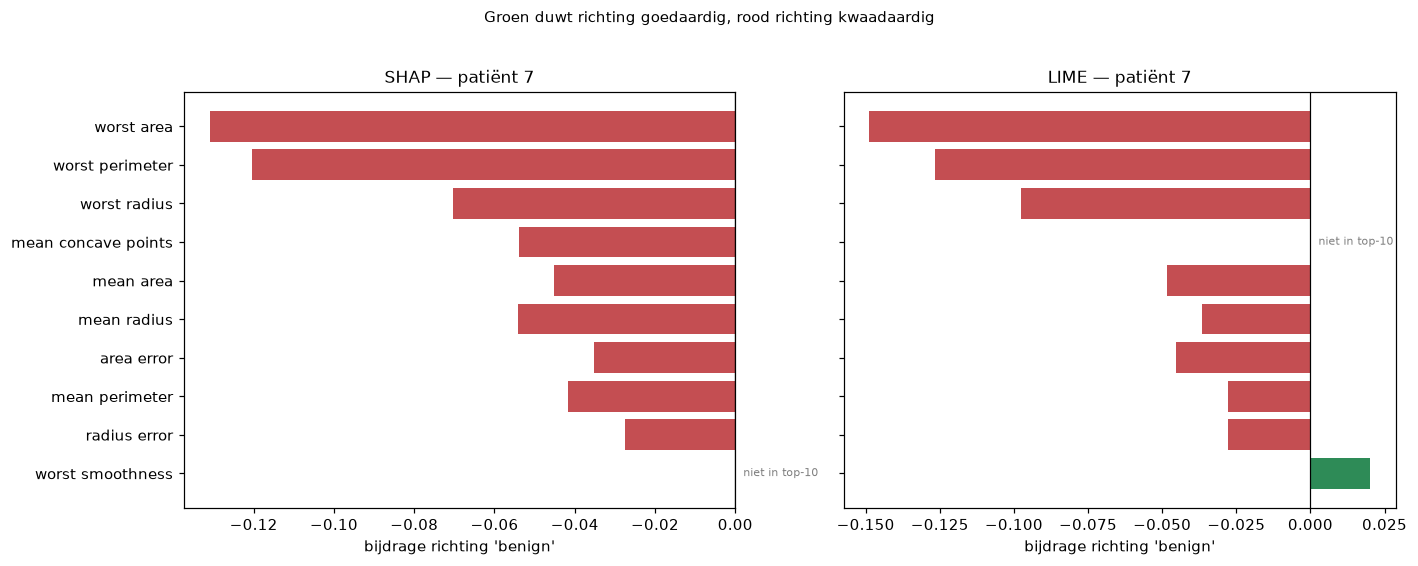

In [29]:
# Visuele vergelijking: twee horizontale barplots, elk op zijn eigen schaal
# maar met dezelfde featurevolgorde -> zo zie je in één oogopslag waar ze
# het eens en oneens zijn.
volgorde = (vergelijking[["SHAP", "LIME"]].abs()
            .div(vergelijking[["SHAP", "LIME"]].abs().sum())   # relatief aandeel
            .mean(axis=1).sort_values(ascending=False).index)
top_features = list(volgorde[:10])[::-1]

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)

for ax, kolom in zip(axes, ["SHAP", "LIME"]):
    waarden = vergelijking.loc[top_features, kolom].fillna(0)
    kleuren = ["#2E8B57" if v > 0 else "#C44E52" for v in waarden]
    ax.barh(range(len(top_features)), waarden.values, color=kleuren)
    ax.set_yticks(range(len(top_features)))
    ax.set_yticklabels(top_features)
    ax.axvline(0, color="black", lw=0.8)
    ax.set_title(f"{kolom} — patiënt {i}", fontsize=11)
    ax.set_xlabel("bijdrage richting 'benign'")
    # Features die deze methode niet in zijn top-10 had, markeren we.
    for k, f in enumerate(top_features):
        if pd.isna(vergelijking.loc[f, kolom]):
            ax.text(0, k, "  niet in top-10", va="center", fontsize=7, color="grey")

fig.suptitle("Groen duwt richting goedaardig, rood richting kwaadaardig",
             fontsize=10, y=1.02)
plt.tight_layout()
plt.show()

In [30]:
# Zijn de twee methodes het EENS? Twee vragen, twee getallen.
gedeeld = vergelijking[["SHAP", "LIME"]].dropna()

rho = (gedeeld.abs().div(gedeeld.abs().sum())      # relatief aandeel per methode
       .corr(method="spearman").iloc[0, 1])
tekens = (np.sign(gedeeld["SHAP"]) == np.sign(gedeeld["LIME"])).mean()

print(f"Features die beide methodes noemen            : {len(gedeeld)}")
print(f"Spearman-rangcorrelatie over die features     : {rho:.3f}")
print(f"Aandeel features dat dezelfde kant op duwt    : {tekens:.0%}")
print()
print("Het teken is het belangrijkste: zijn beide methodes het erover eens of een")
print("feature richting goedaardig of kwaadaardig duwt? De exacte rangorde mag")
print("verschillen - dat is inherent aan twee methodes die iets anders meten.")

Features die beide methodes noemen            : 8
Spearman-rangcorrelatie over die features     : 0.881
Aandeel features dat dezelfde kant op duwt    : 100%

Het teken is het belangrijkste: zijn beide methodes het erover eens of een
feature richting goedaardig of kwaadaardig duwt? De exacte rangorde mag
verschillen - dat is inherent aan twee methodes die iets anders meten.


## De samenvattende tabel voor je slides

| | **SHAP** | **LIME** |
|---|---|---|
| **Wat meet het?** | Eerlijke verdeling van de predictie over de features | Coëfficiënten van een lokale lineaire benadering |
| **Vorm van de uitleg** | een getal per feature | een regel met een drempelwaarde per feature |
| **Referentiepunt** | de gemiddelde voorspelling over de data | geen — puur lokaal |
| **Betrouwbaarheid** | bij bomen exact berekend | benadering; kwaliteit af te lezen aan `exp.score` |
| **Deterministisch** | ja (bij bomen) | nee, tenzij je een seed zet |
| **Snelheid hier** | hele testset in één keer, < 1 s | ~1 s per instantie, telkens opnieuw |
| **Globale uitleg** | ja, door lokale uitleg te aggregeren | nee, LIME is puur lokaal |
| **Gecorreleerde features** | verdeelt het krediet over de correlerende features | kan willekeurig één van de correlerende features kiezen |
| **Leesbaarheid** | getallen op de schaal van de output | regels met drempels ("`worst area > 1034.25`") — vaak intuïtiever |
| **Grootste zwakte** | duur bij niet-boommodellen | geen garanties, instabiel |

### Wie heeft er gelijk?

Ze beantwoorden een subtiel andere vraag:

- **SHAP**: *"Dit is jouw eerlijke aandeel in de predictie, gemiddeld over alle scenario's."*
- **LIME**: *"Dit is de richting waarin het model hier lokaal helt."*

**De praktische regel:** wijzen beide methodes dezelfde features met hetzelfde teken aan — zoals
hierboven grotendeels het geval is — dan is je uitleg robuust. **Wijken ze sterk af, dan is dát
je belangrijkste bevinding**: het model is lokaal grillig, of je features zijn sterk gecorreleerd.
Gebruik uitlegmethodes dus zoals je meetinstrumenten gebruikt: **meer dan één**.

In de praktijk: **gebruik SHAP als standaard** (theoretisch onderbouwd, ook globaal bruikbaar) en
**LIME als second opinion**, of wanneer je publiek regels prettiger leest dan getallen.